# New Dataset – Step 1: Metric Scores

This notebook computes the same complexity measures as in the paper
*"A Multi-Metric Evaluation and Comparison of Large Language Models for German Easy Language Translation"*
for the **New dataset** (4 LLMs × 3 approaches × 10 texts).

**Models**
* `deepseek-v4-flash-0731`
* `gemma-4-31b-it`
* `meta-llama-3.1-8b-instruct`
* `qwen3.5-397b-a17b`

**Texts:** 10 English source texts (`Source_Texts_English`) – 5 legal/administrative (`legal_1–5`, European Commission
press releases) and 5 medical (`medical_1–5`, EMA news). Their official German versions are in `Source_Texts_German`.

**Approaches (all end in German Easy Language)**

| Name | Pipeline | Folder |
|---|---|---|
| **Original** | official German source text (human, reference) | `Source_Texts_German` |
| **Approach_1** | English → English Easy → German Easy | `<model>/Approach_1/DE_translated_easy_from_easy` |
| **Approach_2** | English → standard German → German Easy | `<model>/Approach_2/DE_translated_easy` |
| **Approach_3** | English → German Easy (direct) | `<model>/Approach_3/DE_easy_direct` |

The **Original** is the same for all models (same role as the `*B` files in the old data).

**Output:** `New dataset/<model>/Matrix_Scores_<model>.csv` and box plots in `New dataset/<model>/plots/`.
No CoNLL-U files are generated.


In [1]:
# !pip install pyphen
# !python -m spacy download de_core_news_lg

In [2]:
import os
import re
import pandas as pd
import numpy as np
import spacy
import pyphen
import matplotlib.pyplot as plt
import seaborn as sns

DATA_DIR = "New dataset"

MODELS = [
    "deepseek-v4-flash-0731",
    "gemma-4-31b-it",
    "meta-llama-3.1-8b-instruct",
    "qwen3.5-397b-a17b",
]

VERSIONS = {
    "Original":   "Source_Texts_German",
    "Approach_1": "{model}/Approach_1/DE_translated_easy_from_easy",
    "Approach_2": "{model}/Approach_2/DE_translated_easy",
    "Approach_3": "{model}/Approach_3/DE_easy_direct",
}

TEXT_IDS = [f"{domain}_{i}" for domain in ["legal", "medical"] for i in range(1, 6)]

C:\Users\Khushi\AppData\Local\Programs\Python\Python313\Lib\site-packages\cupy\_environment.py:215: UserWarning: CUDA path could not be detected. Set CUDA_PATH environment variable if CuPy fails to load.
  warnings.warn(


## Loading and cleaning the texts

The same cleaning is applied to the Original and to the LLM outputs. The LLM outputs contain Markdown (`**bold**`, `*` / `•` / `-` bullets, `#` headings) and one output starts with
*"Hier ist der übersetzte Text in Deutscher Leichte Sprache:"*. These are removed before scoring.

Easy Language texts put one sentence per line, and headings / list items often have no final punctuation.
So every line is treated as one sentence: a `.` is added if the line does not end with `.`, `!` or `?`.
(In the old notebooks `\n` was replaced by a space, which merged headings into the next sentence.)


In [3]:
def clean_text(text):
    lines = []
    for line in text.splitlines():
        line = line.strip()
        if not line or line.startswith("Hier ist"):
            continue
        if set(line) <= set("-*_=# "):            # separator lines like --- or ***
            continue
        line = re.sub(r"^[#>*•\-–\s]+", "", line)   # headings and bullets
        line = re.sub(r"^\d+[.)]\s+", "", line)      # numbered lists
        line = line.replace("**", "").replace("__", "").replace("*", "")
        line = line.strip()
        if not line:
            continue
        if line[-1] not in ".!?":
            line += "."
        lines.append(line)
    return " ".join(lines)


def load_model_texts(model):
    rows = []
    for text_id in TEXT_IDS:
        row = {"ID": text_id, "Domain": text_id.split("_")[0].capitalize()}
        for version, folder in VERSIONS.items():
            path = os.path.join(DATA_DIR, folder.format(model=model), f"DE_{text_id}.txt")
            with open(path, encoding="utf-8") as f:
                row[version] = clean_text(f.read())
        rows.append(row)
    return pd.DataFrame(rows)


texts = {model: load_model_texts(model) for model in MODELS}
texts["gemma-4-31b-it"].head()

,ID,Domain,Original,Approach_1,Approach_2,Approach_3
0,legal_1,Legal,Verbraucherschutzbehörden verstärken Maßnahmen...,Verbraucher-Gruppen aus der EU wollen Menschen...,"Mehr Schutz für Leute, die Videospiele spielen...",Schutz für Spieler beim Kauf in Videospielen. ...
1,legal_2,Legal,Kommission verhängt Geldbuße in Höhe von 40 Mi...,Die Europäische Kommission hat eine Strafe an ...,Die EU-Kommission bestraft die Firma Kingspan....,Die EU-Kommission bestraft die Firma Kingspan....
2,legal_3,Legal,Kommission registriert Europäische Bürgeriniti...,Die Europäische Kommission hat eine neue „Euro...,Die EU-Kommission hat eine neue Bürger-Initiat...,Die EU-Kommission hat eine neue Bürger-Initiat...
3,legal_4,Legal,Kommission schlägt 5-Punkte-Plan zur Stärkung ...,Die EU-Kommission hat einen neuen Plan. Der Pl...,Die EU will die Grenzen besser schützen. Die E...,Die EU-Kommission hat einen Plan gemacht. Der ...
4,legal_5,Legal,Kommission verklagt Bulgarien wegen unzureiche...,Die Europäische Kommission verklagt Bulgarien....,Die EU-Kommission verklagt Bulgarien. Es geht ...,Die EU-Kommission verklagt Bulgarien vor dem E...


## spaCy model

The paper used `de_core_news_sm`. Here `de_core_news_lg` is used because the small model has **no word vectors**,
so the Word Rarity measure (`not has_vector and not is_stop`) would just count all non-stop words.
With the large model, Word Rarity really counts words that are missing from the spaCy vocabulary.


In [4]:
nlp = spacy.load("de_core_news_lg")
dic = pyphen.Pyphen(lang="de_DE")

# Every text is parsed only once and re-used by all metrics
_doc_cache = {}

def get_doc(text):
    if text not in _doc_cache:
        _doc_cache[text] = nlp(text)
    return _doc_cache[text]


def count_syllables(word):
    return max(1, dic.inserted(word).count("-") + 1)

# Lexical Measures

### TTR (Type-Token Ratio)

$$\text{TTR} = \frac{\text{Number of Unique Words (Types)}}{\text{Total Number of Words (Tokens)}}$$

Lower TTR = more repetition = closer to Easy Language. Note: TTR depends on text length.

In [5]:
def compute_ttr(text):
    doc = get_doc(text)
    words = [token.text.lower() for token in doc if token.is_alpha]
    if not words:
        return 0.0
    return round(len(set(words)) / len(words), 3)

### Lexical Density (LD)

$$\text{LD} = \frac{\text{Number of Content Words (NOUN, VERB, ADJ, ADV)}}{\text{Total Number of Words}}$$

Lower LD = less information per word = easier.

In [6]:
def compute_lexical_density(text):
    doc = get_doc(text)
    words = [token for token in doc if token.is_alpha]
    if not words:
        return 0.0
    content_words = [token for token in words if token.pos_ in {"NOUN", "VERB", "ADJ", "ADV"}]
    return round(len(content_words) / len(words), 3)

### Word Rarity (WR)

Proportion of words that are **not stop words** and have **no word vector** in the spaCy vocabulary.
Lower WR = more common vocabulary = easier.

In [7]:
def compute_word_rarity(text):
    doc = get_doc(text)
    words = [token.text.lower() for token in doc if token.is_alpha]
    if not words:
        return 0.0
    rare_words = [w for w in words if not nlp.vocab[w].has_vector and not nlp.vocab[w].is_stop]
    return round(len(rare_words) / len(words), 3)

# Syntactic Measures

### MDD (Mean Dependency Distance)

$$\text{MDD} = \frac{\sum |\text{position}_{\text{head}} - \text{position}_{\text{dependent}}|}{\text{Number of dependencies}}$$

Only non-root, non-punctuation dependencies. Lower MDD = simpler sentences.

In [8]:
def compute_mdd(text):
    doc = get_doc(text)
    distances = [abs(token.head.i - token.i) for token in doc
                 if token.dep_ != "ROOT" and not token.is_punct]
    if not distances:
        return 0.0
    return round(sum(distances) / len(distances), 3)

### Subordination Index (SI)

$$\text{SI} = \frac{\text{Number of Subordinate Clauses}}{\text{Total Number of Clauses (Finite Verbs)}}$$

A finite verb whose dependency label is not `ROOT` counts as a subordinate clause. Lower SI = fewer subordinate clauses.

In [9]:
def compute_subordination_index(text):
    doc = get_doc(text)
    finite_verbs = [token for token in doc
                    if token.pos_ in {"VERB", "AUX"} and "Fin" in token.morph.get("VerbForm")]
    if not finite_verbs:
        return 0.0
    subordinate = sum(1 for token in finite_verbs if token.dep_ != "ROOT")
    return round(subordinate / len(finite_verbs), 3)

### Dependency Crossings (Cross)

Two dependency arcs *cross* when they intersect if drawn above the sentence.

**Change compared to the paper:** the paper used the raw *number* of crossings. The texts in the new dataset differ a lot
in length (≈150–600 words), and a longer text automatically has more crossings. So here we use the
**Crossing Index** (as in the explanation of the original notebook):

$$\text{Cross} = \frac{\text{Number of Crossing Arcs}}{\text{Number of Dependencies}} \times 100$$

i.e. crossings per 100 dependencies. Lower = more linear, simpler syntax.

In [10]:
def compute_dependency_crossings(text):
    doc = get_doc(text)
    total_crossings = 0
    total_arcs = 0

    for sent in doc.sents:
        arcs = []
        for token in sent:
            if token.i == token.head.i or token.is_punct:
                continue
            arcs.append((min(token.head.i, token.i), max(token.head.i, token.i)))
        total_arcs += len(arcs)

        for i in range(len(arcs)):
            for j in range(i + 1, len(arcs)):
                a_start, a_end = arcs[i]
                b_start, b_end = arcs[j]
                if (a_start < b_start < a_end < b_end) or (b_start < a_start < b_end < a_end):
                    total_crossings += 1

    if total_arcs == 0:
        return 0.0
    return round(total_crossings / total_arcs * 100, 3)

# Readability Measures

### Wiener Sachtextformel (WSF)

**Change compared to the paper:** the old implementation used the average number of *characters* per word
instead of the percentage of long words, so the formula was not the real WSF. Here the
**first Wiener Sachtextformel** (Bamberger & Vanecek, 1984) is used:

$$\text{WSF} = 0.1935 \cdot MS + 0.1672 \cdot SL + 0.1297 \cdot IW - 0.0327 \cdot ES - 0.875$$

* MS = % of words with 3 or more syllables
* SL = average sentence length (words)
* IW = % of words with more than 6 letters
* ES = % of words with one syllable

The result is a German school grade (4 = very easy … 15 = very difficult). **Lower = easier.**

In [11]:
def wiener_sachtextformel(text):
    doc = get_doc(text)
    sentences = list(doc.sents)
    words = [token.text for token in doc if token.is_alpha]
    if not words or not sentences:
        return 0.0

    syllables = [count_syllables(w) for w in words]
    ms = sum(1 for s in syllables if s >= 3) / len(words) * 100
    sl = len(words) / len(sentences)
    iw = sum(1 for w in words if len(w) > 6) / len(words) * 100
    es = sum(1 for s in syllables if s == 1) / len(words) * 100

    wsf = 0.1935 * ms + 0.1672 * sl + 0.1297 * iw - 0.0327 * es - 0.875
    return round(wsf, 2)

### LIX (Lesbarkeitsindex)

$$\text{LIX} = \frac{\text{Words}}{\text{Sentences}} + \frac{\text{Long Words (> 6 letters)} \times 100}{\text{Words}}$$

Lower = easier.

In [12]:
def lix_score(text):
    doc = get_doc(text)
    sentences = list(doc.sents)
    words = [token.text for token in doc if token.is_alpha]
    if not words or not sentences:
        return 0.0
    long_words = sum(1 for w in words if len(w) > 6)
    return round(len(words) / len(sentences) + long_words * 100 / len(words), 2)

### Amstad's Flesch Reading Ease (FRE)

$$\text{FRE}_{DE} = 180 - \text{ASL} - (58.5 \times \text{ASW})$$

ASL = average sentence length, ASW = average syllables per word. **Higher = easier.**

In [13]:
def flesch_reading_ease_amstad(text):
    doc = get_doc(text)
    sentences = list(doc.sents)
    words = [token.text for token in doc if token.is_alpha]
    if not words or not sentences:
        return 0.0
    asl = len(words) / len(sentences)
    asw = sum(count_syllables(w) for w in words) / len(words)
    return round(180 - asl - 58.5 * asw, 2)

### Gunning Fog Index (Fog)

$$\text{Fog} = 0.4 \times (\text{ASL} + \text{PCW})$$

PCW = % of complex words (3+ syllables, no stop words, no named entities). Lower = easier.

In [14]:
def gunning_fog_index(text):
    doc = get_doc(text)
    sentences = list(doc.sents)
    words = [token for token in doc if token.is_alpha]
    if not words or not sentences:
        return 0.0
    asl = len(words) / len(sentences)
    complex_words = [t for t in words
                     if count_syllables(t.text) >= 3 and not t.is_stop and not t.ent_type_]
    pcw = len(complex_words) / len(words) * 100
    return round(0.4 * (asl + pcw), 2)

# Computing all metrics

In [15]:
METRIC_FUNCTIONS = {
    "TTR":   compute_ttr,
    "LD":    compute_lexical_density,
    "WR":    compute_word_rarity,
    "MDD":   compute_mdd,
    "SI":    compute_subordination_index,
    "Cross": compute_dependency_crossings,
    "WSF":   wiener_sachtextformel,
    "LIX":   lix_score,
    "FRE":   flesch_reading_ease_amstad,
    "Fog":   gunning_fog_index,
}

def compute_all_metrics(df):
    df = df.copy()
    for metric, func in METRIC_FUNCTIONS.items():
        for version in VERSIONS:
            df[f"{metric}_{version}"] = df[version].apply(func)
    return df


scores = {}
for model in MODELS:
    scores[model] = compute_all_metrics(texts[model])
    out_path = os.path.join(DATA_DIR, model, f"Matrix_Scores_{model}.csv")
    scores[model].to_csv(out_path, index=False)
    print("Saved:", out_path)

Saved: New dataset\deepseek-v4-flash-0731\Matrix_Scores_deepseek-v4-flash-0731.csv


Saved: New dataset\gemma-4-31b-it\Matrix_Scores_gemma-4-31b-it.csv


Saved: New dataset\meta-llama-3.1-8b-instruct\Matrix_Scores_meta-llama-3.1-8b-instruct.csv


Saved: New dataset\qwen3.5-397b-a17b\Matrix_Scores_qwen3.5-397b-a17b.csv


## Mean scores per model (Original vs. the 3 approaches)

In [16]:
def mean_table(df):
    table = pd.DataFrame({
        version: [df[f"{metric}_{version}"].mean() for metric in METRIC_FUNCTIONS]
        for version in VERSIONS
    }, index=list(METRIC_FUNCTIONS))
    return table.round(3)

for model in MODELS:
    print(f"\n===================== {model} =====================")
    print(mean_table(scores[model]))


===================== deepseek-v4-flash-0731 =====================
       Original  Approach_1  Approach_2  Approach_3
TTR       0.490       0.448       0.490       0.481
LD        0.489       0.481       0.487       0.487
WR        0.097       0.046       0.046       0.057
MDD       3.301       2.425       1.989       2.263
SI        0.406       0.265       0.121       0.199
Cross     2.404       1.427       0.657       0.794
WSF      13.380       7.391       6.769       7.878
LIX      62.641      41.087      37.462      41.627
FRE      27.705      60.467      63.286      58.330
Fog      21.027      10.846       9.606      11.099

===================== gemma-4-31b-it =====================
       Original  Approach_1  Approach_2  Approach_3
TTR       0.490       0.539       0.557       0.583
LD        0.489       0.484       0.487       0.484
WR        0.097       0.029       0.029       0.032
MDD       3.301       1.966       2.023       2.075
SI        0.406       0.143       0.164 

## Box plots

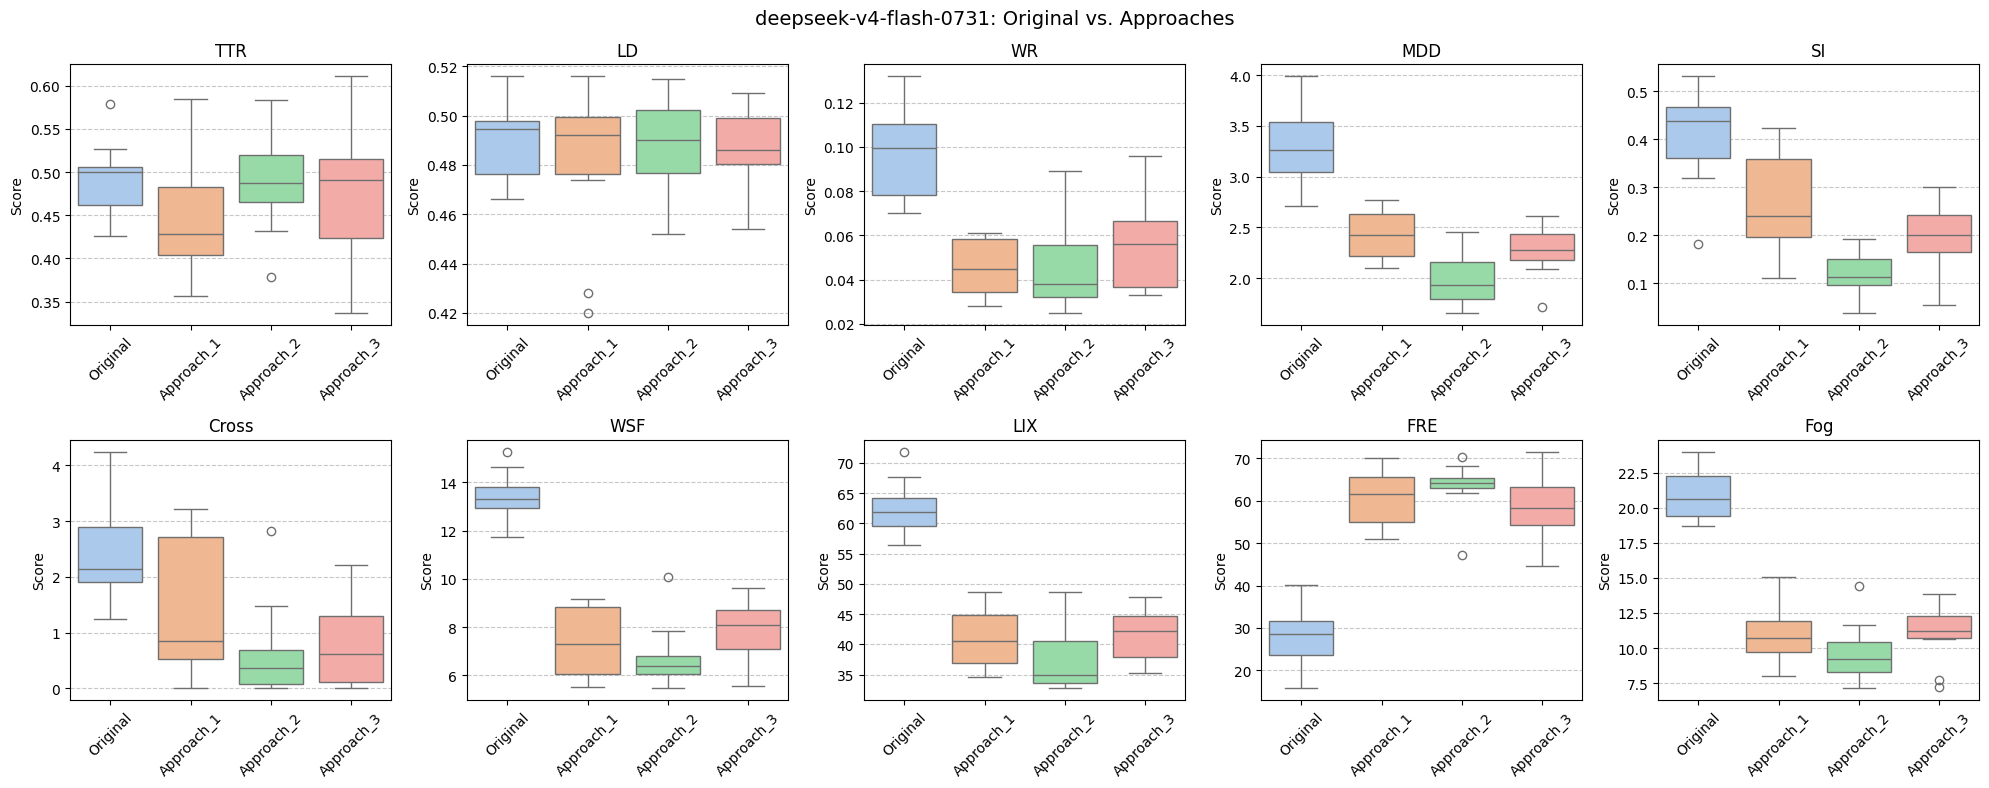

Plot saved to: New dataset\deepseek-v4-flash-0731\plots\deepseek-v4-flash-0731_metrics_boxplot.png


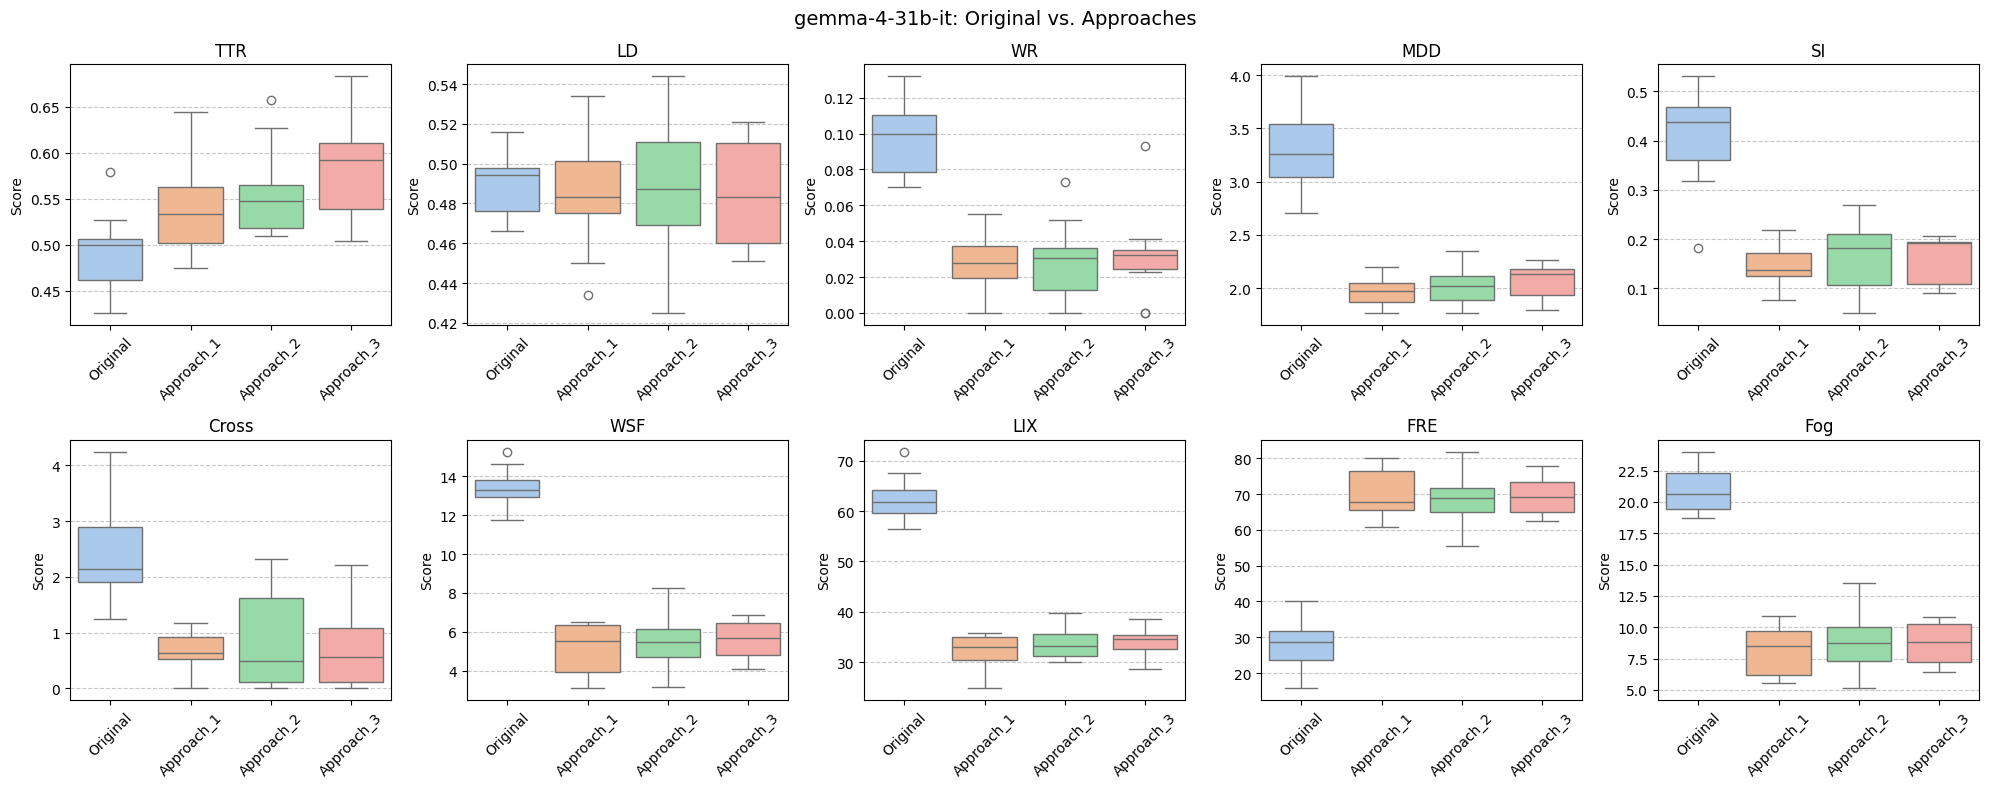

Plot saved to: New dataset\gemma-4-31b-it\plots\gemma-4-31b-it_metrics_boxplot.png


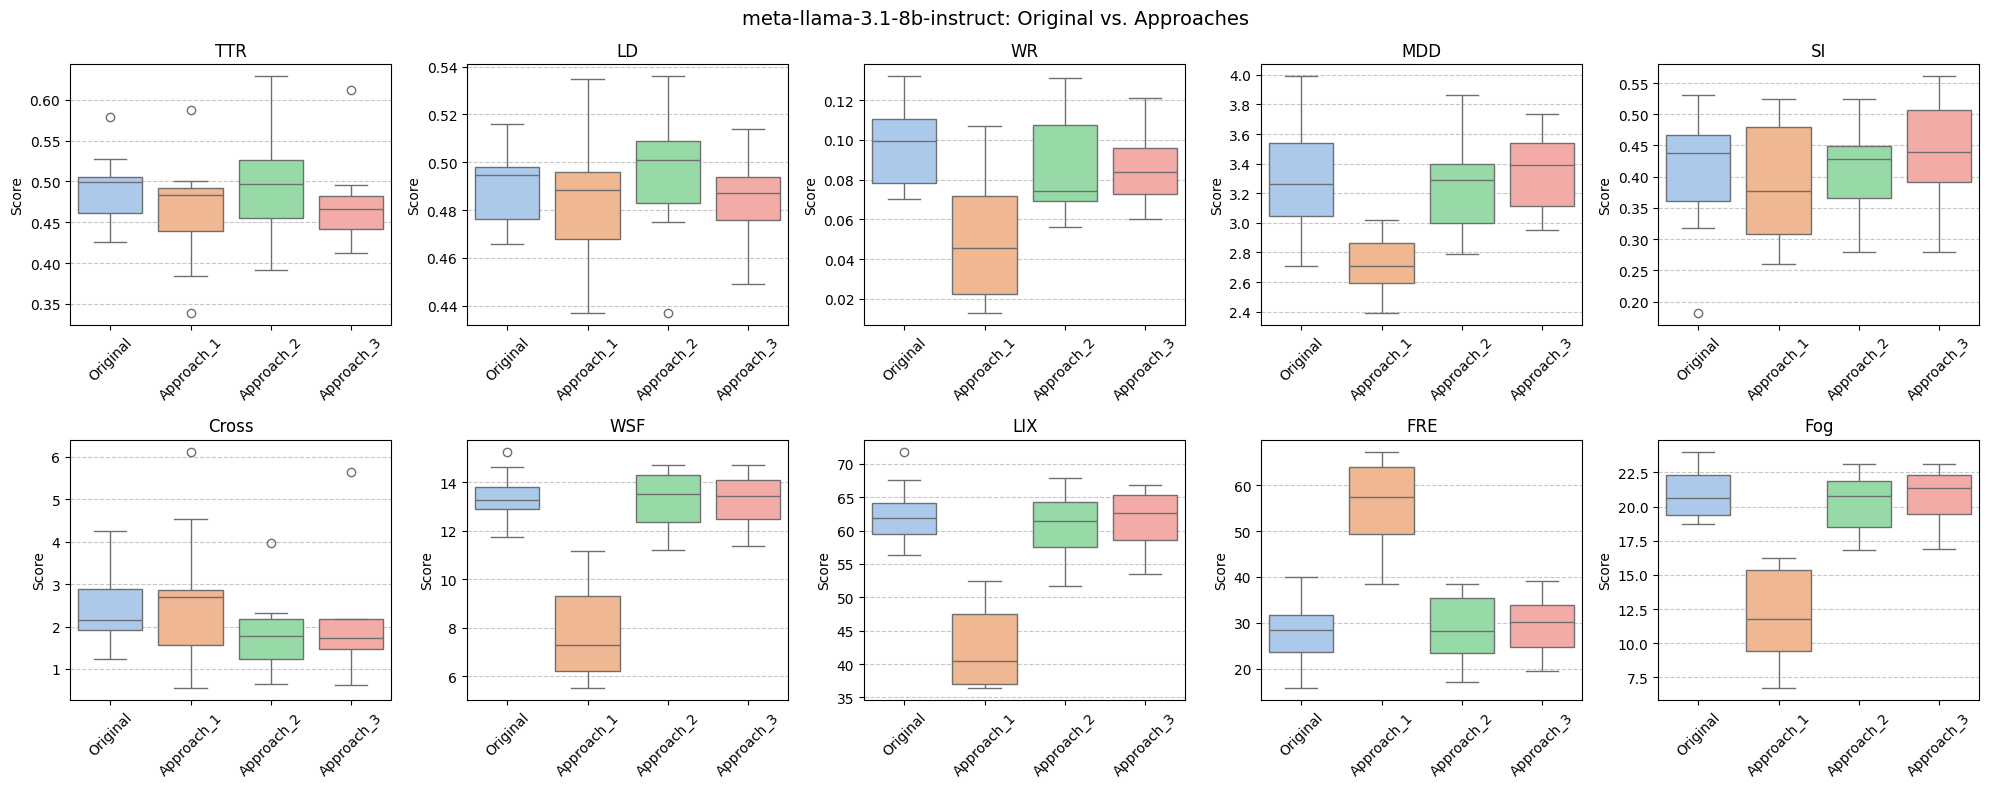

Plot saved to: New dataset\meta-llama-3.1-8b-instruct\plots\meta-llama-3.1-8b-instruct_metrics_boxplot.png


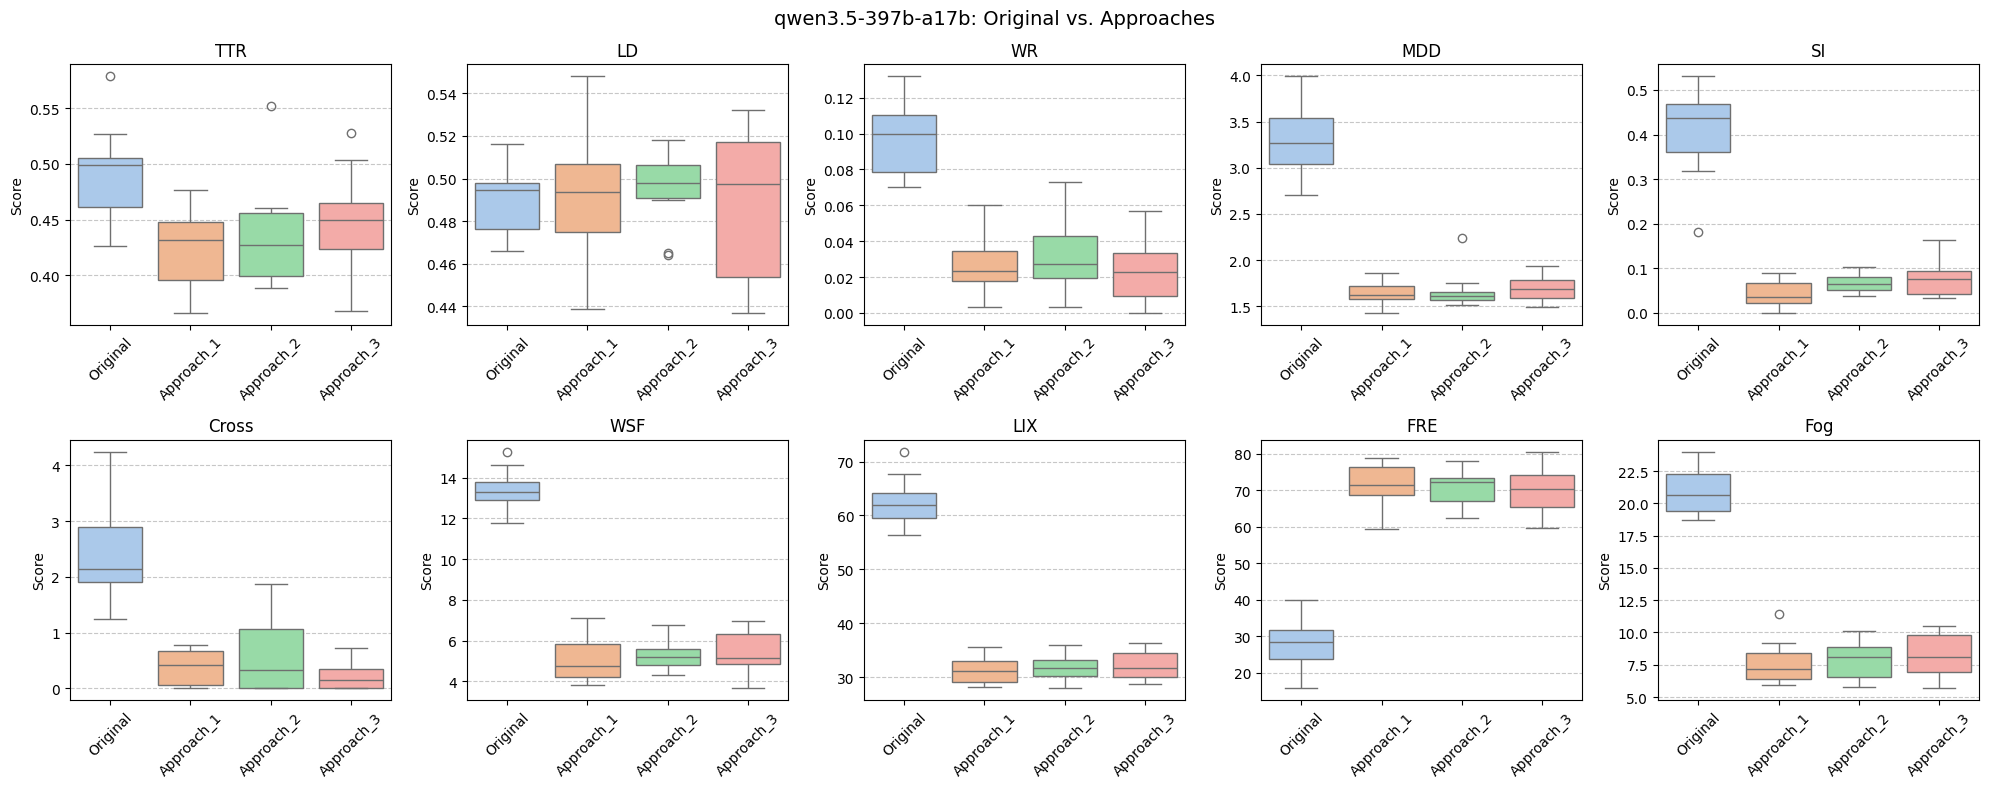

Plot saved to: New dataset\qwen3.5-397b-a17b\plots\qwen3.5-397b-a17b_metrics_boxplot.png


In [17]:
def plot_model_boxplots(df, model, output_dir):
    fig, axes = plt.subplots(2, 5, figsize=(20, 8))
    axes = axes.flatten()

    for ax, metric in zip(axes, METRIC_FUNCTIONS):
        cols = [f"{metric}_{version}" for version in VERSIONS]
        melted = df.melt(value_vars=cols, var_name="Version", value_name="Score")
        melted["Version"] = melted["Version"].str.replace(f"{metric}_", "")
        sns.boxplot(data=melted, x="Version", y="Score", hue="Version", palette="pastel", legend=False, ax=ax)
        ax.set_title(metric)
        ax.set_xlabel("")
        ax.tick_params(axis="x", rotation=45)
        ax.grid(axis="y", linestyle="--", alpha=0.7)

    fig.suptitle(f"{model}: Original vs. Approaches", fontsize=14)
    plt.tight_layout()

    os.makedirs(output_dir, exist_ok=True)
    file_path = os.path.join(output_dir, f"{model}_metrics_boxplot.png")
    plt.savefig(file_path, dpi=150)
    plt.show()
    plt.close()
    print("Plot saved to:", file_path)


for model in MODELS:
    plot_model_boxplots(scores[model], model, os.path.join(DATA_DIR, model, "plots"))